# Traffic Volume Forecaster
Predict the next hour traffic volume on a highway using time, weather and past traffic.


**Data:** Metro Interstate Traffic Volume (UCI). If the download fails the notebook makes a small synthetic sample and tells you.

**Models:** same hour yesterday (baseline), Linear Regression, Random Forest. Metric is WAPE (MAPE breaks on near-zero values).

In [1]:
!pip install -q pandas numpy scikit-learn matplotlib

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import urllib.request, zipfile, io

url = "https://archive.ics.uci.edu/static/public/492/metro+interstate+traffic+volume.zip"
try:
    raw = urllib.request.urlopen(url, timeout=40).read()
    z = zipfile.ZipFile(io.BytesIO(raw))
    fname = [n for n in z.namelist() if "csv" in n][0]
    if fname.endswith(".gz"):
        df = pd.read_csv(z.open(fname), compression="gzip")
    else:
        df = pd.read_csv(z.open(fname))
    print("real data loaded:", df.shape)
except Exception as e:
    print("download failed, making synthetic data instead:", e)
    t = pd.date_range("2016-01-01", periods=24*700, freq="h")
    hour = t.hour.values
    day = t.dayofweek.values
    vol = 3000 + 1500*np.sin((hour-6)/24*2*np.pi) + 800*(hour==8) + 900*(hour==17)
    vol = vol - 600*(day>=5) + np.random.normal(0, 250, len(t))
    df = pd.DataFrame({"date_time": t, "traffic_volume": vol.clip(0).round(),
                       "temp": 285 + 10*np.sin(np.arange(len(t))/(24*365)*2*np.pi) + np.random.normal(0,2,len(t)),
                       "rain_1h": 0.0, "snow_1h": 0.0, "clouds_all": np.random.randint(0,100,len(t)),
                       "holiday": "None"})

df.head()

real data loaded: (48204, 9)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [3]:
df["date_time"] = pd.to_datetime(df["date_time"])
df = df.drop_duplicates(subset="date_time").sort_values("date_time")
df["is_holiday"] = (df["holiday"].fillna("None") != "None").astype(int)
df = df[["date_time", "traffic_volume", "temp", "rain_1h", "snow_1h", "clouds_all", "is_holiday"]]
df = df.set_index("date_time").asfreq(pd.offsets.Hour(1))
print("missing hours before fill:", df["traffic_volume"].isna().sum())
df = df.interpolate(limit=24)
df["is_holiday"] = df["is_holiday"].fillna(0)
df = df.dropna()
print(df.shape)

missing hours before fill: 11976
(44629, 6)


In [4]:
df["hour"] = df.index.hour
df["dayofweek"] = df.index.dayofweek
df["month"] = df.index.month
df["lag_1"] = df["traffic_volume"].shift(1)
df["lag_24"] = df["traffic_volume"].shift(24)
df["lag_168"] = df["traffic_volume"].shift(168)
df["avg_last_24"] = df["traffic_volume"].shift(1).rolling(24).mean()
df = df.dropna()

features = ["hour", "dayofweek", "month", "temp", "rain_1h", "snow_1h", "clouds_all", "is_holiday",
            "lag_1", "lag_24", "lag_168", "avg_last_24"]
split = int(len(df) * 0.8)
train = df.iloc[:split]
test = df.iloc[split:]
print("train rows:", len(train), "test rows:", len(test))
print("test starts at:", test.index[0])

train rows: 35568 test rows: 8893
test starts at: 2017-09-25 11:00:00


In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

def wape(actual, pred):
    return np.sum(np.abs(actual - pred)) / np.sum(np.abs(actual)) * 100

y_test = test["traffic_volume"].values

base_pred = test["lag_24"].values
print("Baseline (same hour yesterday) WAPE:", round(wape(y_test, base_pred), 2), "%")

lr = LinearRegression()
lr.fit(train[features], train["traffic_volume"])
lr_pred = lr.predict(test[features])
print("Linear Regression WAPE:", round(wape(y_test, lr_pred), 2), "%")

rf = RandomForestRegressor(n_estimators=100, max_depth=15, n_jobs=-1, random_state=42)
rf.fit(train[features], train["traffic_volume"])
rf_pred = rf.predict(test[features])
print("Random Forest WAPE:", round(wape(y_test, rf_pred), 2), "%")

Baseline (same hour yesterday) WAPE: 17.04 %
Linear Regression WAPE: 10.67 %
Random Forest WAPE: 4.58 %


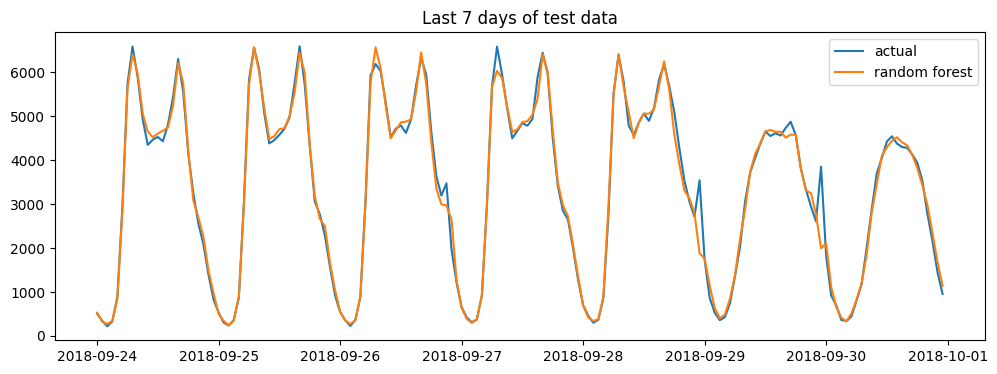

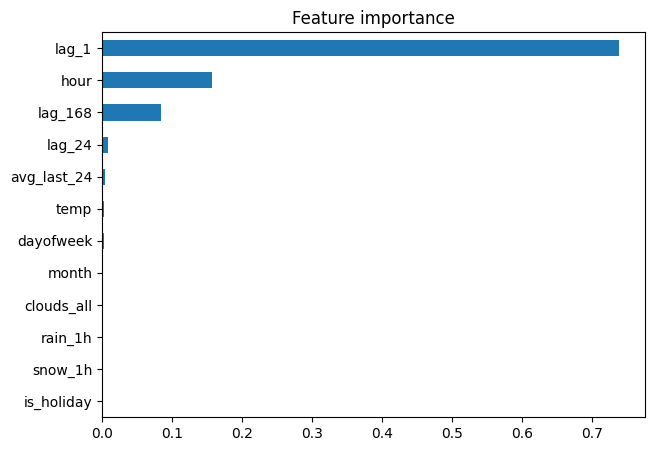

In [6]:
last = test.iloc[-24*7:]
plt.figure(figsize=(12,4))
plt.plot(last.index, last["traffic_volume"], label="actual")
plt.plot(last.index, rf_pred[-24*7:], label="random forest")
plt.title("Last 7 days of test data")
plt.legend()
plt.show()

imp = pd.Series(rf.feature_importances_, index=features).sort_values()
imp.plot(kind="barh", figsize=(7,5), title="Feature importance")
plt.show()

In [7]:
errors = pd.DataFrame({"hour": test["hour"].values, "error": np.abs(y_test - rf_pred)})
print("average error by hour of day:")
print(errors.groupby("hour")["error"].mean().round(0))

print()
print("Summary")
print("Baseline WAPE:", round(wape(y_test, base_pred), 2))
print("Linear WAPE:", round(wape(y_test, lr_pred), 2))
print("Random Forest WAPE:", round(wape(y_test, rf_pred), 2))

average error by hour of day:
hour
0      99.0
1      48.0
2      36.0
3      33.0
4      49.0
5     108.0
6     181.0
7     232.0
8     214.0
9     179.0
10    146.0
11    116.0
12    133.0
13    141.0
14    135.0
15    186.0
16    237.0
17    200.0
18    172.0
19    146.0
20    127.0
21    226.0
22    263.0
23    243.0
Name: error, dtype: float64

Summary
Baseline WAPE: 17.04
Linear WAPE: 10.67
Random Forest WAPE: 4.58


In [ ]:

# ============================================================
# UNIVERSAL COLAB PROJECT AUTO-SAVE
# Structure: Parent Folder / Notebook Name / All Project Files
# ============================================================

import os
import json
import shutil
from pathlib import Path
from google.colab import auth, _message
from googleapiclient.discovery import build
from googleapiclient.http import MediaFileUpload
from google.auth import default

# 1. DESTINATION GOOGLE DRIVE FOLDER
PARENT_FOLDER_ID = "1RJ_KbIui8TyupB2kr3c-N93lt2OE0nAk"

# 2. AUTHENTICATE
auth.authenticate_user()
credentials, _ = default()
drive = build("drive", "v3", credentials=credentials)

# 3. DETECT CURRENT NOTEBOOK
notebook_data = _message.blocking_request("get_ipynb")

if "ipynb" in notebook_data:
    notebook_data = notebook_data["ipynb"]

project_name = (
    notebook_data.get("metadata", {})
    .get("colab", {})
    .get("name", "")
)

if not project_name:
    project_name = input("Enter your Colab notebook name (e.g. RAG): ").strip()

project_name = Path(project_name).stem

if not project_name:
    raise ValueError("Project name is missing.")

print("Project detected:", project_name)

# 4. FIND OR CREATE PROJECT FOLDER
query = (
    f"'{PARENT_FOLDER_ID}' in parents "
    f"and name = '{project_name}' "
    "and mimeType = 'application/vnd.google-apps.folder' "
    "and trashed = false"
)

results = drive.files().list(
    q=query,
    fields="files(id,name)",
    supportsAllDrives=True,
    includeItemsFromAllDrives=True
).execute()

if results.get("files"):
    PROJECT_FOLDER_ID = results["files"][0]["id"]
else:
    folder = drive.files().create(
        body={
            "name": project_name,
            "mimeType": "application/vnd.google-apps.folder",
            "parents": [PARENT_FOLDER_ID]
        },
        fields="id"
    ).execute()

    PROJECT_FOLDER_ID = folder["id"]

# 5. UPLOAD FILES WITHOUT ZIP
SKIP_DIRS = {
    "drive", "sample_data", ".config",
    ".cache", "__pycache__"
}

uploaded = 0
failed = []

def find_existing_file(name, parent_id):
    q = (
        f"'{parent_id}' in parents "
        f"and name = '{name}' "
        "and trashed = false"
    )
    found = drive.files().list(
        q=q,
        fields="files(id)",
        supportsAllDrives=True,
        includeItemsFromAllDrives=True
    ).execute()
    return found.get("files", [])

def upload_file(local_path, parent_id):
    global uploaded

    filename = os.path.basename(local_path)

    metadata = {
        "name": filename,
        "parents": [parent_id]
    }

    media = MediaFileUpload(
        local_path,
        resumable=True
    )

    existing = find_existing_file(filename, parent_id)

    if existing:
        drive.files().update(
            fileId=existing[0]["id"],
            media_body=media,
            supportsAllDrives=True
        ).execute()
    else:
        drive.files().create(
            body=metadata,
            media_body=media,
            fields="id",
            supportsAllDrives=True
        ).execute()

    uploaded += 1
    print("Saved:", filename)

def upload_directory(local_dir, drive_parent_id):
    for item in os.scandir(local_dir):

        if item.is_dir(follow_symlinks=False):

            if item.name in SKIP_DIRS:
                continue

            existing = find_existing_file(
                item.name, drive_parent_id
            )

            if existing:
                subfolder_id = existing[0]["id"]
            else:
                result = drive.files().create(
                    body={
                        "name": item.name,
                        "mimeType": "application/vnd.google-apps.folder",
                        "parents": [drive_parent_id]
                    },
                    fields="id",
                    supportsAllDrives=True
                ).execute()
                subfolder_id = result["id"]

            upload_directory(item.path, subfolder_id)

        elif item.is_file(follow_symlinks=False):
            try:
                upload_file(item.path, drive_parent_id)
            except Exception as error:
                failed.append((item.name, str(error)))
                print("Upload failed:", item.name, error)

# 6. SAVE EXECUTED NOTEBOOK
notebook_path = f"/content/{project_name}.ipynb"

with open(notebook_path, "w", encoding="utf-8") as f:
    json.dump(notebook_data, f, ensure_ascii=False, indent=2)

# 7. UPLOAD PROJECT FILES
upload_directory("/content", PROJECT_FOLDER_ID)

# 8. FINAL REPORT
print("\n======================================")
print("PROJECT BACKUP COMPLETED")
print("======================================")
print("Project:", project_name)
print("Uploaded files:", uploaded)
print("Failed files:", len(failed))
print(
    "Folder:",
    f"https://drive.google.com/drive/folders/{PROJECT_FOLDER_ID}"
)

if failed:
    print("\nFailed uploads:")
    for name, error in failed:
        print(name, error)